# 02 Baseline

Before training any model we need a reference point: an error value on its own says little. An average error of 200 MW is good if a trivial approach is off by 400 MW, and worthless if it is off by 180 MW. We therefore start with a **baseline**, a deliberately simple forecast that involves no learning, and every later model must beat it.

## Baseline: same hour one week earlier

The forecast for a given hour is the load observed exactly one week (168 hours) before:

$$\hat y(t) = y(t - 168\,\mathrm{h}).$$

This assumes that nothing changes from one week to the next. Since consecutive weeks are very similar (see the weekly plot in `01_explore`), this is a strong baseline. It fails where something does change: public holidays, sudden temperature changes, and transitions between seasons.

## Chronological split

| Set | Period | Purpose |
|---|---|---|
| Training | 2020–2023 | fit model parameters |
| Validation | 2024 | compare models and choose settings |
| Test | 2025 | used **once** at the very end |

The split follows time instead of randomness because (1) the model will be used to forecast the future from the past, and the evaluation should reproduce this situation, and (2) consecutive hours are strongly correlated: with a random split, test points would lie next to training points, the model would only interpolate, and the error would be too optimistic (leakage).

## Metrics

- **MAE** (mean absolute error), in MW: $\frac{1}{n}\sum_t |y(t) - \hat y(t)|$
- **MAPE** (mean absolute percentage error), in %: $\frac{100}{n}\sum_t \frac{|y(t) - \hat y(t)|}{y(t)}$

The baseline has no parameters, so it needs no training data; we evaluate it on the validation year and look at when it fails.

## Data

We load the cleaned quarter-hourly series from `01_explore` (kWh per 15 minutes, UTC, labels mark the end of each interval), convert it to average power in MW (× 4 / 1000) and aggregate to hourly resolution. As in `01_explore`, each hour is formed from the four quarter hours (h−1, h] and labelled with its end time h.

Expected:
- **Number of hours:** 2020 and 2024 are leap years with 366 × 24 = 8,784 hours each; 2021–2023 and 2025 have 365 × 24 = 8,760 hours each. In total 2 × 8,784 + 4 × 8,760 = 52,608 hours.
- **First timestamp:** the first hour of 2020 in Swiss local time runs from 00:00 to 01:00 on 1 January 2020 (CET = UTC+1). Its end, 01:00 local time, is 2020-01-01 00:00 UTC.
- **Last timestamp:** the last hour of 2025 ends at 00:00 local time on 1 January 2026, which is 2025-12-31 23:00 UTC.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Cleaned quarter-hourly series from 01_explore (kWh per 15 min, UTC, end-of-interval labels)
load = pd.read_parquet("../data/processed/load_2020_2025.parquet")["load"]

# Convert to average power in MW and aggregate to hourly resolution
y = (load * 4 / 1000).resample("h", closed="right", label="right").mean()
y.name = "load_mw"

print(len(y))
print(y.index.min(), y.index.max())

52608
2020-01-01 00:00:00+00:00 2025-12-31 23:00:00+00:00


## Split

Years are taken in Swiss local time. Each hour is assigned to the year in which it starts (the hour labelled 1 January 00:00 local time covers the last hour of the previous year).

Expected: training 2020–2023 with 8'784 + 3 × 8'760 = 35'064 hours, validation 2024 with 8'784 hours (leap year), test 2025 with 8'760 hours. The validation set runs from 2024-01-01 00:00 UTC (end of the first hour of 2024, 01:00 local time) to 2024-12-31 23:00 UTC (end of the last hour, 00:00 local time on 1 January 2025).

In [2]:
# Local calendar year of each hour; subtract one hour because labels mark the end of the interval
year = (y.index - pd.Timedelta(hours=1)).tz_convert("Europe/Zurich").year

# Split into training, validation, and test sets
y_train = y[year <= 2023]
y_val = y[year == 2024]
y_test = y[year == 2025]

print(len(y_train), len(y_val), len(y_test))
print(y_val.index.min(), y_val.index.max())

35064 8784 8760
2024-01-01 00:00:00+00:00 2024-12-31 23:00:00+00:00


## Baseline forecast

The baseline is computed on the full series and then restricted to the validation year, so that the first week of 2024 uses the last week of 2023 (information that is available at forecast time).

In [3]:
# Forecast: value of the same hour one week (168 hours) earlier
y_hat = y.shift(168)
# Align the forecast with the validation set
y_hat_val = y_hat.loc[y_val.index]

# Check for missing values in the forecast
print(y_hat_val.isna().sum())
# Compare the actual and baseline forecast values for the first few hours of the validation set
print(pd.DataFrame({"actual": y_val, "baseline": y_hat_val}).head())

0
                                actual     baseline
2024-01-01 00:00:00+00:00  5739.248154  5364.960593
2024-01-01 01:00:00+00:00  5710.915366  5174.075896
2024-01-01 02:00:00+00:00  5576.793738  5009.418622
2024-01-01 03:00:00+00:00  5389.995073  4888.506984
2024-01-01 04:00:00+00:00  5235.865674  4819.034144


Reading the table: the first row is the hour from 00:00 to 01:00 Swiss time on 1 January 2024 (timestamp in UTC, marking the end of the hour). The actual load was 5'739 MW; the baseline forecast is the value of the same hour one week earlier, on 25 December 2023: 5'365 MW. The error of about 374 MW (6.5 %) is large because the baseline transfers Christmas night, with exceptionally low demand, to New Year's night. This is a first example of the baseline's weakness on public holidays.

In [4]:
def mae(y_true, y_pred):
    # Mean absolute error, in the unit of y (MW)
    return (y_true - y_pred).abs().mean()


def mape(y_true, y_pred):
    # Mean absolute percentage error, in %
    return 100 * ((y_true - y_pred).abs() / y_true).mean()


print(f"Baseline (same hour last week), validation 2024: "
      f"MAE = {mae(y_val, y_hat_val):.0f} MW, MAPE = {mape(y_val, y_hat_val):.2f} %")

Baseline (same hour last week), validation 2024: MAE = 362 MW, MAPE = 5.84 %


On the validation year 2024 the baseline has an MAE of 362 MW and a MAPE of 5.84 %. Every model must beat these values.

## Error analysis

We compute the MAPE per day (Swiss local date) and look at the days where the baseline fails most.

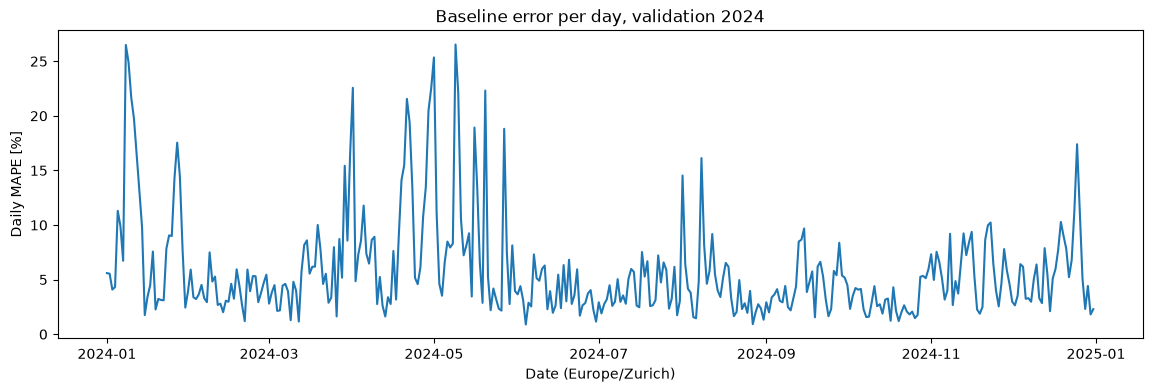

2024-05-09    26.534230
2024-01-08    26.491009
2024-05-01    25.349299
2024-01-09    24.901711
2024-04-01    22.567004
2024-04-30    22.536483
2024-05-20    22.314576
2024-05-10    22.109075
2024-01-10    21.662950
2024-04-21    21.555824
2024-04-29    20.504656
2024-01-11    19.757295
2024-04-22    19.428745
2024-05-16    18.927690
2024-05-27    18.813762
Name: load_mw, dtype: float64


In [5]:
# Local date of each hour; subtract one hour because labels mark the end of the interval
day = (y_val.index - pd.Timedelta(hours=1)).tz_convert("Europe/Zurich").date

# Absolute percentage error per hour, averaged per day
ape = 100 * (y_val - y_hat_val).abs() / y_val
daily_mape = ape.groupby(day).mean()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(daily_mape.index, daily_mape.values)
ax.set_xlabel("Date (Europe/Zurich)")
ax.set_ylabel("Daily MAPE [%]")
ax.set_title("Baseline error per day, validation 2024")
plt.show()

# The 15 days with the largest error
print(daily_mape.sort_values(ascending=False).head(15))

The daily error is around 5 % on ordinary days, with peaks of up to 26 %. The largest errors occur on public holidays (Easter Monday 1 April, 1 May, Ascension 9 May and the bridge day 10 May, Whit Monday 20 May) and exactly one week later, when the holiday is used as the forecast for an ordinary day (8–11 January after the New Year holidays, 16 May, 27 May). This explains the cluster in April and May, where the movable holidays fall. Some peaks may also reflect weather changes, which we will check once temperature data is added. Holiday and temperature features are therefore the most promising additions for the models in stage 2.

## Second baseline: average over the previous four weeks

The one-week baseline suffers from single unusual weeks (holidays, and their echo one week later). We therefore test a second baseline: the mean of the same hour in the **four** previous weeks,

$$\hat y(t) = \tfrac14 \sum_{k=1}^{4} y(t - k \cdot 168\,\mathrm{h}).$$

Averaging damps single unusual weeks, but reacts more slowly to trends such as the seasonal decline in spring.